In [161]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import SMS_map
importlib.reload(SMS_map)
from SMS_map import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
import DTT_func
importlib.reload(DTT_func)
from DTT_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_thermal_study_plot
importlib.reload(PaP_quantitative_thermal_study_plot)
from PaP_quantitative_thermal_study_plot import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\PaP_calculate_quantitative_signal')
import PaP_quantitative_thermal_study_func 
importlib.reload(PaP_quantitative_thermal_study_func)
from PaP_quantitative_thermal_study_func import *



os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Linear_spectra_meas')
from Spectra_computation_func import *
import Spectra_computation_func
importlib.reload(Spectra_computation_func)
from Spectra_computation_func  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\SMS_map')
from FWHM_treatment_func import *
import FWHM_treatment_func
importlib.reload(FWHM_treatment_func)
from FWHM_treatment_func  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

# Get the raw experimental data

In [162]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study'
#dir_root += r'\Silice thick 4,5 - D1 zone1'
dir_root += r'\Silice thick 4,5 - D2 zone1'
#dir_root += r'\Membrane 3,5 - ND3,5-5'
#dir_root += r'\Sapphire 2,3 - NDd zone 3'



dir_raw_data = dir_root + r'\Extinction variation calculation'
os.chdir(dir_root)

fname_thermic = 'thermic_raw_data.dat'
Data_thermic = get_raw_data(dir_raw_data, fname_thermic)


In [163]:
for key in Data_thermic :
    print(key)

date
lambda_probe
detuning
detuning_normalised
x_LP2
P_ini
polar
A_th
A_th_err
tau_th
tau_th_err
A2_th
A2_th_err
tau2_th
tau2_th_err
Comment


# Get the FWHM calibration of the probe

In [164]:
# get calib
if dir_root.endswith(r'\Silice thick 4,5 - D1 zone1') :
    dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\Jun 2025'


    Source_list = ['OPO', 'SHG']
    FWHM_data = get_FWHM_data(dir_calib, Source_list)
    WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

    WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


if dir_root.endswith(r'\Silice thick 4,5 - D2 zone1') :
    dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\2026-04'


    Source_list = ['OPO', 'SHG']
    FWHM_data = get_FWHM_data(dir_calib, Source_list)
    WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_1D_mean']

    WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']


if dir_root.endswith(r'\Membrane 3,5 - ND3,5-5') :
    dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\March 2025'


    Source_list = ['OPO', 'SHG']
    FWHM_data = get_FWHM_data(dir_calib, Source_list)
    WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

    WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']

if dir_root.endswith(r'\Sapphire 2,3 - NDd zone 3') :
    dir_calib = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Calibrations\Nanoscope_2 - FWHM\March 2025'
        
    Source_list = ['OPO', 'SHG']
    FWHM_data = get_FWHM_data(dir_calib, Source_list)
    WL_calib, FWHM_calib = FWHM_data['WL'], FWHM_data['FWHM_2D_mean']

    WL_calib_probe, FWHM_calib_probe = WL_calib['OPO'], FWHM_calib['OPO']

# Get the linear spectra of the object
in the folder 'linear specrta'

In [165]:
#define delta_y
delta_y = 300e-9

#get spectra
if dir_root.endswith(r'\Sapphire 2,3 - NDd zone 3') :
    Spectra_dic_tot = Spectra_computation(dir_root, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '21-Jan-2025-Spectre_theta_0', force_recomputation=False, spectra_title = '21-Jan-2025-Spectre_theta_0', method='fine')
    
if dir_root.endswith(r'\Membrane 3,5 - ND3,5-5') :
    Spectra_dic_tot = Spectra_computation(dir_root, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '13-Mar-2025-Spectre_theta_90', force_recomputation=False, spectra_title = '13-Mar-2025-Spectre_theta_90', method='fine')

if dir_root.endswith(r'\Silice thick 4,5 - D1 zone1') :
    Spectra_dic_tot = Spectra_computation(dir_root, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '01-Jul-2025-Spectre_theta_170', force_recomputation=False, spectra_title = '01-Jul-2025-Spectre_theta_170', method='fine')


if dir_root.endswith(r'\Silice thick 4,5 - D2 zone1') :
    Spectra_dic_tot = Spectra_computation(dir_root, 'Linear spectra', WL_calib, FWHM_calib, delta_y, Source_list, other_title = '15-Apr-2026-Spectre_theta_0', force_recomputation=False, spectra_title = '15-Apr-2026-Spectre_theta_0', method='fine')



Spectra_dic = Spectra_dic_tot['file']['OPO']

Linear spectra already treated


In [166]:
for key in Spectra_dic :
    print(key)

Lambda
DTT
Voff
V
DTT_corr (1e-3)
Sigma (nm2)
Sigma_err (nm2)


# Get the pump calibration information

In [167]:
os.chdir(dir_root)
fname_pump = 'pump_characteristic.dat'
Pump_calib_data = get_raw_data(dir_root, fname_pump)

# Quantitative data treatment

Here we calculate the corrected sigmal of $A_p = A_{th,1} + A_{th,2}$

Two corrections must be implemented :

1) Take into account the absorption of the nano-object. cf my obsidian notes on PaP for more detail : $$  A_{p, corr} = A_p (1-\frac{\sigma_\mathrm{ext,0}(\lambda)}{S_\mathrm{probe}(\lambda)})$$

2) add a correction to take into account that we normalize with the photodiode signal and not the LIA signal at the right modulation. cf my obsidian notes aswell : $${DTT} = \alpha_\mathrm{PaP} \frac{\Delta S_{LIA}|_F}{S_{DMM}}$$

In [168]:
alpha_PaP = 1 #Conversion coefficient from the raw DTT signal. For Nathan's measurement, the 2.55 coeff needed
              # was already implemented in the DTT software in the experiment room. It can be set to 1 here.
if dir_root.endswith(r'\Silice thick 4,5 - D2 zone1') :
    alpha_PaP = 2.55 # For this study the coefficient wasn't there


compute_corrected_DTT_signal(Data_thermic, Spectra_dic, FWHM_calib_probe, WL_calib_probe, alpha=alpha_PaP, verbose=True)

lda probe = 570.0 nm
Suface S probe = 143376.7 nm2
Ap = 3.4 e-5
Ap error = 1.9 e-5
Ap_corr = 7.9 e-5
Ap_corr error = 3.1 e-5
-----------------------------------------------------
lda probe = 580.0 nm
Suface S probe = 148577.3 nm2
Ap = 6.5 e-5
Ap error = 2.0 e-5
Ap_corr = 14.5 e-5
Ap_corr error = 3.2 e-5
-----------------------------------------------------
lda probe = 590.0 nm
Suface S probe = 160188.8 nm2
Ap = 13.8 e-5
Ap error = 1.8 e-5
Ap_corr = 29.6 e-5
Ap_corr error = 2.8 e-5
-----------------------------------------------------
lda probe = 600.0 nm
Suface S probe = 163235.0 nm2
Ap = 25.1 e-5
Ap error = 2.5999999999999996 e-5
Ap_corr = 51.2 e-5
Ap_corr error = 3.8 e-5
-----------------------------------------------------
lda probe = 610.0 nm
Suface S probe = 169090.4 nm2
Ap = 42.0 e-5
Ap error = 3.0999999999999996 e-5
Ap_corr = 80.0 e-5
Ap_corr error = 4.2 e-5
-----------------------------------------------------
lda probe = 620.0 nm
Suface S probe = 171889.5 nm2
Ap = 49.9 e-5
Ap 

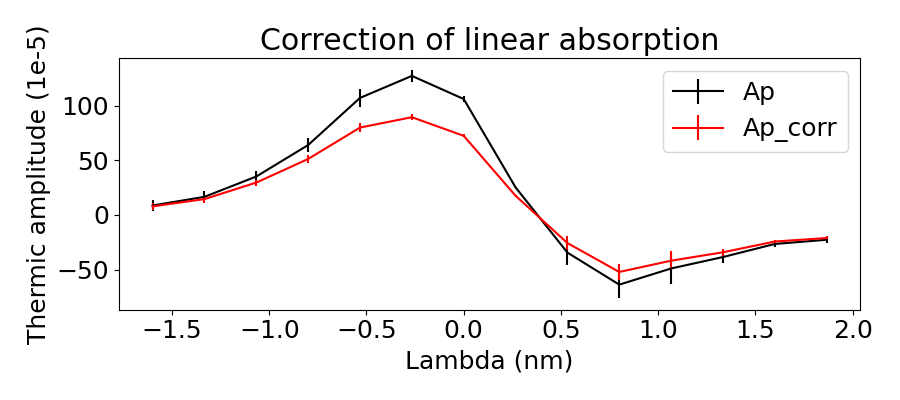

In [169]:
fig, ax  = plt.subplots(figsize=(9,4))
plot_A_raw_coeff(Data_thermic, ax, alpha_PaP=alpha_PaP)
plot_A_corrected_coeff(Data_thermic, ax)

ax.set_title("Correction of linear absorption")
ax.legend()

plt.tight_layout()

# Calculate $\Delta \sigma_\mathrm{ext}$

In [170]:
Compute_delta_sigma_thermic(Data_thermic, FWHM_calib_probe, WL_calib_probe, verbose=False)

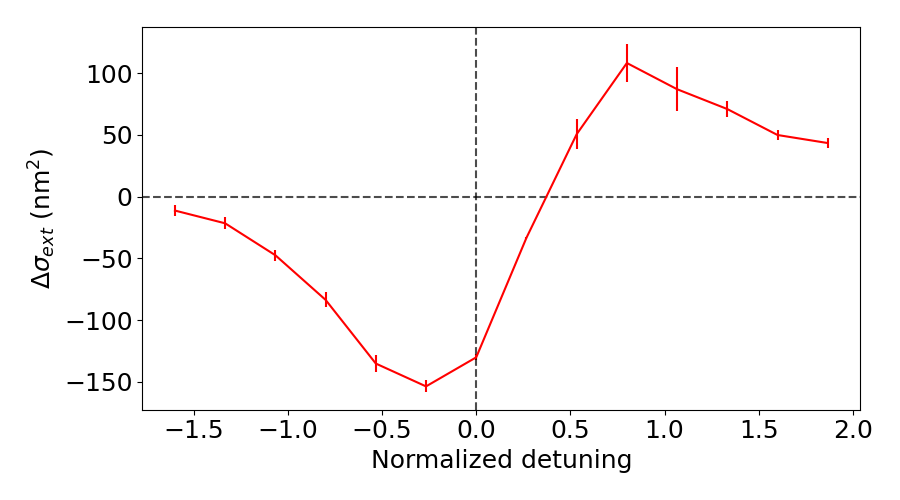

In [171]:
fig, ax  = plt.subplots(figsize=(9,5))

plot_Delta_sigma_thermic(Data_thermic, ax)
plt.tight_layout()

# Calculate $\Delta T_0$

The temparature elevation is defined by $\Delta T_0 = \frac{E_{abs}}{C}$


with $E_{abs} = \sigma_{abs, 0}(\lambda_{pump}) \frac{E_{pulse}}{S_{pump}}$ the absorbed energy at each impulsion

and C = $c_V V$ the thermal capacity of the nanoparticle (V is its volume, $c_V$ its volumic thermal capacity)




### Important parameters

In [172]:
t_chopper = 1 #attenuation coefficient of the mechanical chopper (equal to 1 i the power was measured without the chopper)
f_rep = 80e6 #laser repetition rate
lda_pump = 410 #pump wavelength in nm.
c_V = 	2.492 * 1e6 #Volumic capacity in S.I.

if dir_root.endswith(r'\Sapphire 2,3 - NDd zone 3') :
    sigma_abs_pump = 5415.65  #sigma_abs(lda_pump) in nm2
    D = 92e-9 #diameter
    h = 24e-9 #height


if dir_root.endswith(r'\Membrane 3,5 - ND3,5-5') :
    sigma_abs_pump = 4043.21  #sigma_abs(lda_pump) in nm2
    D = 81e-9 #diameter
    h = 18e-9 #height

if dir_root.endswith(r'\Silice thick 4,5 - D1 zone1') :
    sigma_abs_pump = 7911.18  #sigma_abs(lda_pump) in nm2
    D = 102e-9 #diameter
    h = 22e-9 #height

if dir_root.endswith(r'\Silice thick 4,5 - D2 zone1') : #To be determined
    sigma_abs_pump = 8726  #sigma_abs(lda_pump) in nm2
    D = 109.4e-9 #diameter
    h = 23.5e-9 #height

V = np.pi*h*(D/2)**2

C = V*c_V #total heat capacity of the nanodisk

### Calculated $E_{pulse}$, energy in a single pulse

#### from $E_{pulse} = \frac{P_i t_{chopper} t_{objective}}{f_{rep}}$

In [173]:
compute_E_pulse(Data_thermic, Pump_calib_data, t_chopper, f_rep, verbose=False)

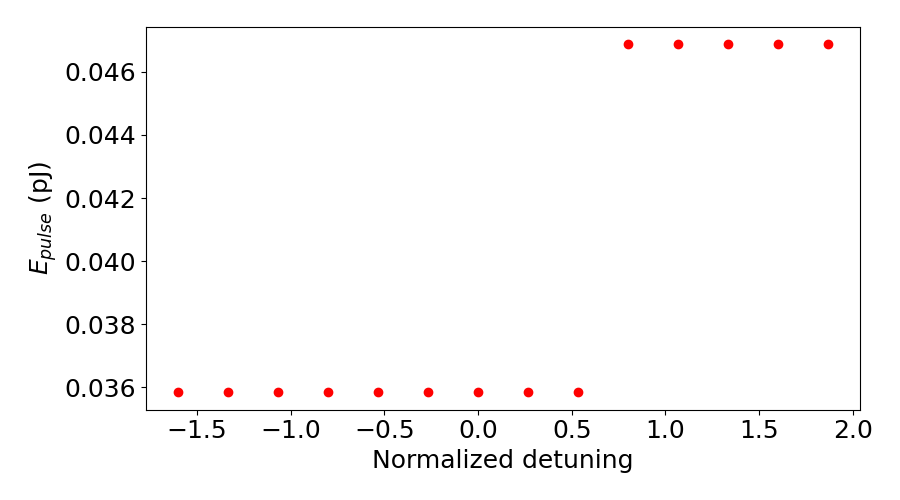

In [174]:
fig, ax  = plt.subplots(figsize=(9,5))

plot_E_pulse(Data_thermic, ax)

plt.tight_layout()

Calculate $\Delta T_0$ from : $$ \Delta T_0 = \frac{E_\mathrm{abs}}{C} =\sigma_\mathrm{abs, 0}(\lambda_\mathrm{pump}) \frac{E_\mathrm{pulse}}{S_\mathrm{pump}C} $$

In [175]:
compute_Delta_T(Data_thermic, Pump_calib_data, sigma_abs_pump, C=C, verbose=False)

Data_thermic['Delta_sigma_th_normalized'] = Data_thermic['Delta_sigma_th']/ Data_thermic['Delta_T']
Data_thermic['Delta_sigma_th_normalized_err'] = np.abs(Data_thermic['Delta_sigma_th_err']/ Data_thermic['Delta_T'])

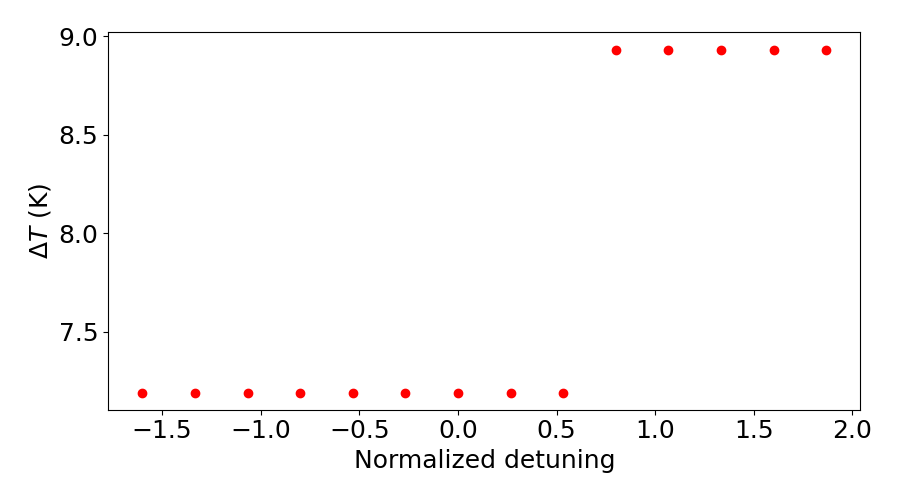

In [176]:
fig, ax  = plt.subplots(figsize=(9,5))

plot_Delta_T(Data_thermic, ax)

plt.tight_layout()

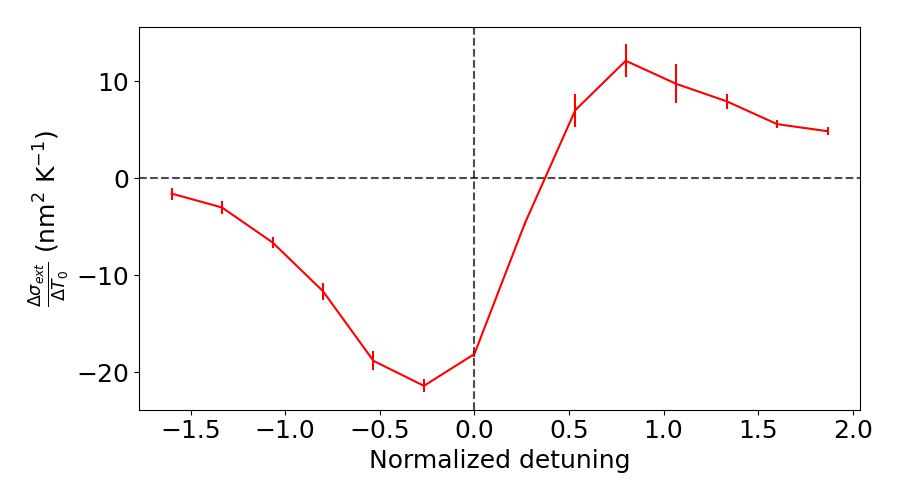

In [177]:
fig, ax  = plt.subplots(figsize=(9,5))

plot_Delta_sigma_thermic_normalized(Data_thermic, ax)
#plot_Delta_sigma_thermic(Data_thermic, ax)

plt.tight_layout()

# Estimate the interface resistance

Check Romain's article : a simple model links the decrase time $\tau$ with the interface conductance G and the thickness of the nanodisks :

$$ \tau = c_V \frac{h}{G}$$

Romain a fait deux mesures et a eu l'estimation G = 60 $\pm$ 10 MW m $^{-2}$ K $^{-1}$ pour les disques avec h = 40 nm et G = 75 $\pm$ 10 MW m $^{-2}$ K $^{-1}$ pour les disques avec h = 18 nm sur du Sapphire

In [178]:
G = c_V*h/Data_thermic['tau_th'][np.argmax(Data_thermic['A_th'])]*1e12
All_G = c_V*h/Data_thermic['tau_th']*1e12


print('G estimé : G = {} MW/m2/K'.format(G*1e-6))
print(' All G estimé : {} MW/m2/K'.format(All_G*1e-6))

for key in Data_thermic :
    #print(key)
    ND = Data_thermic[key]

    #print(ND)


G estimé : G = 47.61138211382113 MW/m2/K
 All G estimé : [45.04769231 46.11181102 40.38758621 41.83       40.95244755 47.61138211
 45.7515625  64.2127193  45.04769231 41.83       48.80166667 43.37925926
 40.78133705 47.11343524] MW/m2/K


# Save_data

In [179]:
full_normalize_sigma(Data_thermic, Spectra_dic)

In [ ]:
# dir_to_save = dir_root + r'\Extinction variation calculation'
# fname = 'Treated_experimental_data_thermic.csv'

# save_treated_PaP_signal_thermic(Data_thermic, dir_to_save, fname)